In [104]:
import mysql.connector
connection = mysql.connector.connect(host='localhost', port=3306, database='guvi', user='root', password="Abcd@1234")
cursor = connection.cursor()

In [31]:
import pandas as pd
cursor.execute('SELECT * FROM products')
df_prod = pd.DataFrame(cursor.fetchall(), columns = [i[0] for i in cursor.description])
df_prod['product_weight_g'] = df_prod['product_weight_g'].astype(float)
df_prod['product_length_cm'] = df_prod['product_length_cm'].astype(float)
df_prod['product_height_cm'] = df_prod['product_height_cm'].astype(float)
df_prod['product_width_cm'] = df_prod['product_width_cm'].astype(float)
df_prod['product_volume'] = df_prod['product_length_cm'] * df_prod['product_height_cm'] * df_prod['product_width_cm']
df_prod.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume
count,32323.000000,32323.000000,32323.000000,32323.000000,32323.000000,32323.000000,32323.000000,32323.000000
mean,48.473378,771.547381,2.188937,2277.242583,30.856604,16.954955,23.207623,16577.400520
std,10.246908,635.223211,1.736824,4279.923909,16.959506,13.637797,12.081176,27069.415782
min,5.000000,4.000000,1.000000,2.000000,7.000000,2.000000,6.000000,168.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000,2880.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000,6859.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,20.000000,30.000000,18499.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000,296208.000000


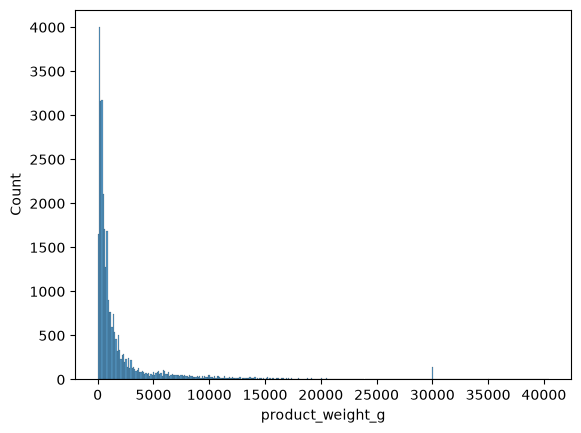

3.607481674039664


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(df_prod, x='product_weight_g')
plt.show()
print(df_prod['product_weight_g'].skew()) # product weight is heavily right skewed

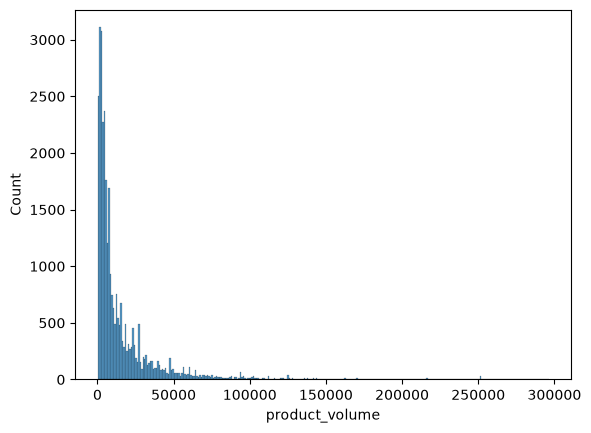

4.1825184980647006


In [ ]:
sns.histplot(df_prod, x='product_volume')
plt.show() 
print(df_prod['product_volume'].skew()) # product volume is heavily right skewed

In [73]:
cursor.execute('SELECT * FROM order_items')
df_item = pd.DataFrame(cursor.fetchall(), columns = [i[0] for i in cursor.description])
df_item['price'] = df_item['price'].astype(float)
df_item['freight_value'] = df_item['freight_value'].astype(float)
df_item.describe()

,order_item_id,shipping_limit_date,price,freight_value
count,108083.000000,108083,108083.000000,108083.000000
mean,1.198912,2018-01-09 11:27:04.915528,120.086467,19.974432
min,1.000000,2016-09-19 23:11:33,0.850000,0.000000
25%,1.000000,2017-09-21 22:53:38.500000,39.900000,13.080000
50%,1.000000,2018-01-29 13:52:42,74.900000,16.280000
75%,1.000000,2018-05-11 16:31:31,134.900000,21.150000
max,21.000000,2020-04-09 22:35:08,6735.000000,409.680000
std,0.709586,NaN,182.179515,15.747215


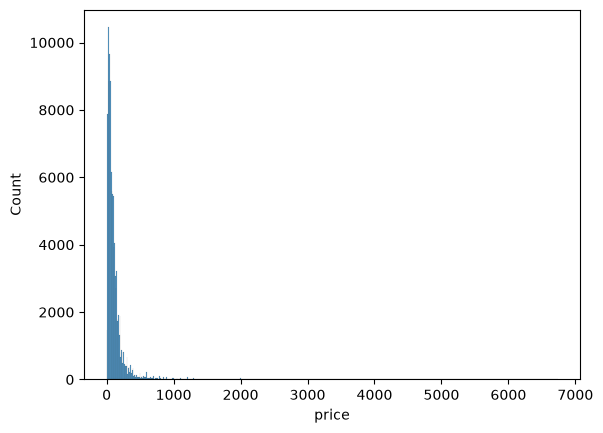

8.00240035228665


In [ ]:
sns.histplot(df_item, x='price')
plt.show() 
print(df_item['price'].skew()) # item price is heavily right skewed

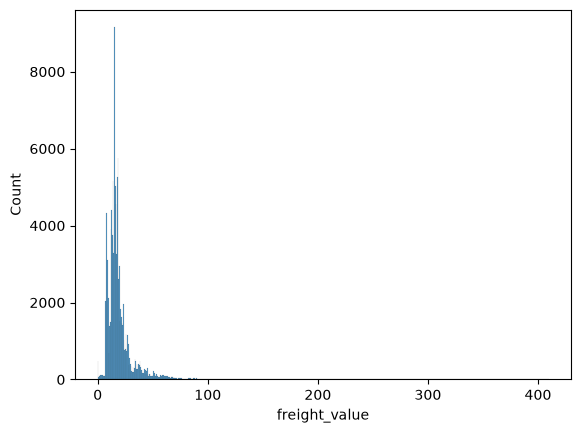

5.662562528569336


In [ ]:
sns.histplot(df_item, x='freight_value')
plt.show()
print(df_item['freight_value'].skew()) # freight value is heavily right skewed

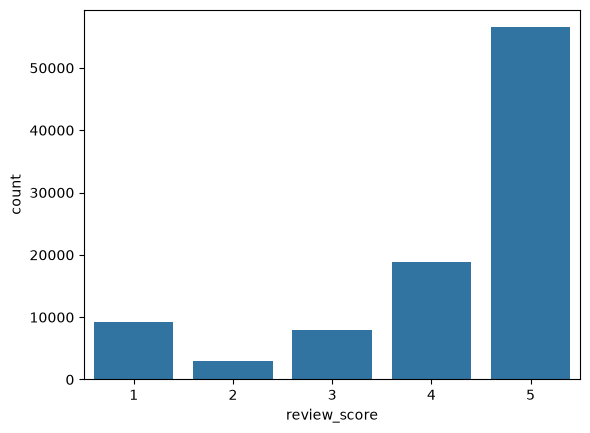

In [ ]:
cursor.execute('SELECT * FROM order_reviews')
df_review = pd.DataFrame(cursor.fetchall(), columns = [i[0] for i in cursor.description])
sns.countplot(df_review, x='review_score')
plt.show() # 5 is the the most common review while 2 is the least

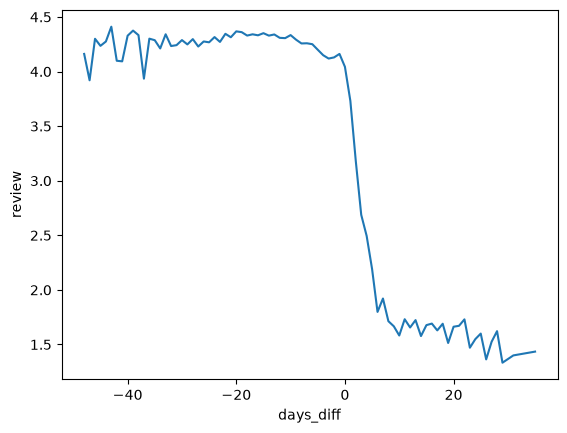

In [ ]:
cursor.execute('SELECT AVG(r.review_score) AS review, (DATEDIFF(o.order_delivered_customer_date, o.order_estimated_delivery_date)) AS days_diff,' \
' COUNT(*) AS count FROM order_reviews AS r INNER JOIN orders AS o ON r.order_id = o.order_id GROUP BY days_diff')
df_bivar = pd.DataFrame(cursor.fetchall(), columns = [i[0] for i in cursor.description])
df_bivar = df_bivar[df_bivar['count'] >= 20]
sns.lineplot(df_bivar, x='days_diff', y='review')
plt.show() # delayed orders negatively affect the review as average review decreases sharply between 0 and 5 days difference


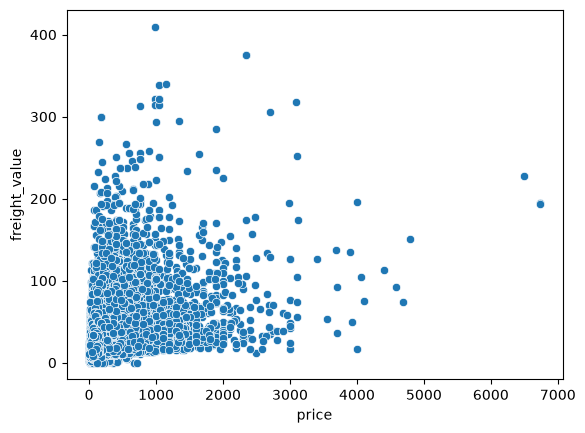

0.4132311153190594


In [ ]:
sns.scatterplot(df_item, x='price', y='freight_value')
plt.show()
print(df_item['price'].corr(df_item['freight_value'])) # there is a weak positive correlation between price and freight_value

<Axes: >

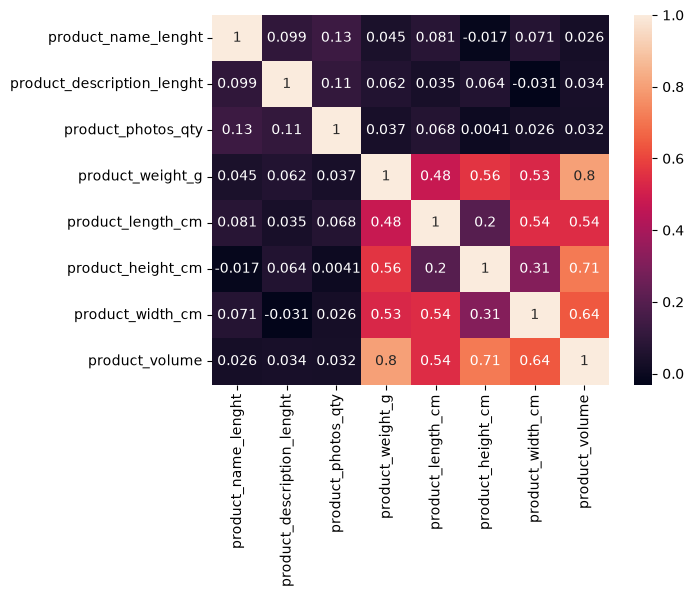

In [ ]:
sns.heatmap(df_prod.drop(columns=['product_id', 'product_category_name']).corr(), annot=True) 
# the strongest correlation is between product weight and volume